# Чтение данных

Данные: 48 городов, 1991 год.

- City (Город): Название города

- Работа (Work): Взвешенное среднее числа рабочих часов, сосчитанное по 12
профессиям

- Цена (Price): Индекс цен 112 товаров и услуг, включая арендную плату за
жилье(значение для Цюриха взято за 100%)

- Заработная плата (Salary): Индекс заработной платы за час работы,
сосчитанный по 12 профессиям после налогов и вычетов (значение для Цюриха
взято за 100%)

In [ ]:
# Библиотеки + Читаем файл

%pip -q install gdown

import gdown
import pandas as pd
import numpy  as np
from sklearn.cluster import KMeans
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

file_id = "1tzLHiEN1BqvjlJaeQToBn0F69n-OQ-0W"


gdown.download(id=file_id, output="Econom_Cities_data.csv", quiet=False)

df_raw = pd.read_csv("Econom_Cities_data.csv", sep=";")

Downloading...
From: https://drive.google.com/uc?id=1tzLHiEN1BqvjlJaeQToBn0F69n-OQ-0W
To: /content/Econom_Cities_data.csv
100%|██████████| 1.18k/1.18k [00:00<00:00, 2.36MB/s]


In [ ]:
# приведем переменные к числовым значениям
cols = ['Work', 'Price', 'Salary']

for col in cols:
    df_raw[col] = pd.to_numeric(
        df_raw[col]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

df_raw[cols] = df_raw[cols].replace(-9999, np.nan)

# Заполняем методом ближайших соседей
df_knn = df_raw.copy()

# Выравниваем масштабы перед поиском соседей.

knn_scaler = StandardScaler()
X_scaled = knn_scaler.fit_transform(df_raw[cols])

# возьмем 5 соседей
imputer = KNNImputer(n_neighbors=5, weights="uniform")
X_filled = imputer.fit_transform(X_scaled)

# Возвращаем часы и индексы в исходные единицы
df_knn[cols] = knn_scaler.inverse_transform(X_filled)


all_cols = ["Work", "Price", "Salary"]

df_scaled = (df_knn[all_cols] - df_knn[all_cols].mean()) / df_knn[all_cols].std(ddof=1)

# Кластеризация

min_samples - минимальное количество точек в этой окрестности, включая саму рассматриваемую точку, необходимое для того, чтобы она считалась ядерной точкой (core point)

eps - Две точки считаются соседями, если расстояние между ними не больше ep. Радиус окретсности


In [ ]:
from sklearn.metrics import silhouette_score

results = []

# Переберем значения eps и min_samples

for eps in np.round(np.arange(0.5, 1.31, 0.1), 2):
    for min_samples in [2, 3, 5, 8, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean").fit_predict(df_scaled)
        mask = labels != -1
        cluster_sizes = (pd.Series(labels[mask]).value_counts().sort_index())
        n_clusters = len(cluster_sizes)

        silhouette = np.nan
        if 2 <= n_clusters < mask.sum():
            silhouette = silhouette_score(df_scaled.loc[mask], labels[mask])

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "cluster_sizes": cluster_sizes.tolist(),
            "noise_count": int((~mask).sum()),
            "noise_pct": round((~mask).mean() * 100, 1),
            "silhouette": silhouette
        })

comparison = pd.DataFrame(results)
display(comparison.round(3))

,eps,min_samples,n_clusters,cluster_sizes,noise_count,noise_pct,silhouette
0,0.5,2,6,"[15, 3, 3, 7, 2, 2]",16,33.3,0.498
1,0.5,3,4,"[15, 3, 3, 7]",20,41.7,0.491
2,0.5,5,1,[12],36,75.0,NaN
3,0.5,8,0,[],48,100.0,NaN
4,0.5,10,0,[],48,100.0,NaN
5,0.6,2,4,"[16, 20, 2, 2]",8,16.7,0.510
6,0.6,3,2,"[16, 20]",12,25.0,0.551
7,0.6,5,2,"[12, 8]",28,58.3,0.721
8,0.6,8,1,[11],37,77.1,NaN
9,0.6,10,1,[10],38,79.2,NaN


# Выбор Параметров

Возьмем значения eps=0.8, min_samples=3

Так как при них получается приемлимое значение силуэта **0.52** и относительно не высокий процент шума **16.7** %

Далее посмотрим, насколько содержательна интерпритация получившихся кластеров

In [ ]:
# Кластеризация с выбранными параметрами
dbscan_1 = DBSCAN(eps=0.8, min_samples=3, metric="euclidean")
dbscan_1.fit(df_scaled)

# Добавляем метки кластеров к данным с заполненными пропусками
df_result = df_knn.copy()
df_result["cluster"] = dbscan_1.labels_

# Показываем города и их показатели для каждого кластера
for cluster in sorted(df_result["cluster"].unique()):
    if cluster != -1:
        print(f"Кластер {cluster}")
        display(df_result.loc[df_result["cluster"] == cluster])

# Отдельно показываем шумовые наблюдения
print("Города, отнесённые к шуму")
display(df_result.loc[df_result["cluster"] == -1])

Кластер 0


,City,Work,Price,Salary,cluster
0,Amsterdam,1714.0,65.6,49.0,0
4,Brussels,1708.0,73.8,50.5,0
8,Chicago,1924.0,73.9,61.9,0
9,Copenhagen,1717.0,91.3,62.9,0
10,Dublin,1759.0,76.0,41.4,0
11,Dusseldorf,1693.0,78.5,60.2,0
12,Frankfurt,1650.0,74.5,60.4,0
16,Houston,1978.0,71.9,46.3,0
22,London,1737.0,84.2,46.2,0
23,Los_Angeles,2068.0,79.8,65.2,0


Кластер 1


,City,Work,Price,Salary,cluster
1,Athens,1792.0,53.8,30.40,1
2,Bogota,2152.0,37.9,11.50,1
3,Bombay,2052.0,30.3,5.30,1
5,Buenos_Aires,1971.0,56.1,12.50,1
6,Cairo,2119.4,37.1,7.30,1
7,Caracas,2041.0,61.0,10.90,1
17,Jakarta,1985.6,43.6,6.58,1
18,Johannesburg,1945.0,51.1,24.00,1
19,Kuala_Lumpur,2167.0,43.5,9.90,1
20,Lagos,1786.0,45.2,2.70,1


Города, отнесённые к шуму


,City,Work,Price,Salary,cluster
13,Geneva,1880.0,95.9,90.3,-1
14,Helsinki,1667.0,113.6,66.6,-1
15,Hong_Kong,2375.0,63.8,27.8,-1
33,Oslo,1583.0,115.5,63.7,-1
40,Stockholm,1805.0,111.3,39.2,-1
42,Taipei,2145.0,84.3,34.5,-1
44,Tokyo,1880.0,115.0,68.0,-1
47,Zurich,1868.0,100.0,100.0,-1


In [ ]:
display(
    df_result.loc[df_result["cluster"] != -1]
    .groupby("cluster")[cols]
    .mean()
    .round(2)
)

,Work,Price,Salary
cluster,,,
0,1792.0,77.53,55.16
1,1968.1,49.19,14.04


**Интерпритация:**

Получили 2 кластера и 8 объектов отнесенных к шуму

Кластер 0: города в развитых старнах, где цены и зарплаты выше чем в кластере 1, количество рабочих часов немного меньше при этом

Кластер 1: города в развивающихся старнах, где цены и зарплаты ниже чем в кластере 0, количество рабочих часов при этом больше

Объекты отнесенные к шуму:

- Жинева и Цюрих - высокие цены и высокие зарплаты
- Осло, Хельсинки, Стокгольм + Токио - высокие цены, при этом зарплаты не такие большие
- Hong_Kong и Taipei - аномально высокое количество рабочих часов



Возьмем значения eps=0.8, min_samples=2

Посмотрим, получится ли с меньшим количеством точек в окрестности, необходимым для образования ядра, выделить дополнительные кластеры из шума

In [ ]:
# Кластеризация с выбранными параметрами
dbscan_2 = DBSCAN(eps=0.8, min_samples=2, metric="euclidean")
dbscan_2.fit(df_scaled)

# Добавляем метки кластеров к данным с заполненными пропусками
df_result = df_knn.copy()
df_result["cluster"] = dbscan_2.labels_

# Показываем города и их показатели для каждого кластера
for cluster in sorted(df_result["cluster"].unique()):
    if cluster != -1:
        print(f"Кластер {cluster}")
        display(df_result.loc[df_result["cluster"] == cluster])

# Отдельно показываем шумовые наблюдения
print("Города, отнесённые к шуму")
display(df_result.loc[df_result["cluster"] == -1])

Кластер 0


,City,Work,Price,Salary,cluster
0,Amsterdam,1714.0,65.6,49.0,0
4,Brussels,1708.0,73.8,50.5,0
8,Chicago,1924.0,73.9,61.9,0
9,Copenhagen,1717.0,91.3,62.9,0
10,Dublin,1759.0,76.0,41.4,0
11,Dusseldorf,1693.0,78.5,60.2,0
12,Frankfurt,1650.0,74.5,60.4,0
16,Houston,1978.0,71.9,46.3,0
22,London,1737.0,84.2,46.2,0
23,Los_Angeles,2068.0,79.8,65.2,0


Кластер 1


,City,Work,Price,Salary,cluster
1,Athens,1792.0,53.8,30.40,1
2,Bogota,2152.0,37.9,11.50,1
3,Bombay,2052.0,30.3,5.30,1
5,Buenos_Aires,1971.0,56.1,12.50,1
6,Cairo,2119.4,37.1,7.30,1
7,Caracas,2041.0,61.0,10.90,1
17,Jakarta,1985.6,43.6,6.58,1
18,Johannesburg,1945.0,51.1,24.00,1
19,Kuala_Lumpur,2167.0,43.5,9.90,1
20,Lagos,1786.0,45.2,2.70,1


Кластер 2


,City,Work,Price,Salary,cluster
13,Geneva,1880.0,95.9,90.3,2
47,Zurich,1868.0,100.0,100.0,2


Кластер 3


,City,Work,Price,Salary,cluster
14,Helsinki,1667.0,113.6,66.6,3
33,Oslo,1583.0,115.5,63.7,3


Города, отнесённые к шуму


,City,Work,Price,Salary,cluster
15,Hong_Kong,2375.0,63.8,27.8,-1
40,Stockholm,1805.0,111.3,39.2,-1
42,Taipei,2145.0,84.3,34.5,-1
44,Tokyo,1880.0,115.0,68.0,-1


In [ ]:
display(
    df_result.loc[df_result["cluster"] != -1]
    .groupby("cluster")[cols]
    .mean()
    .round(2)
)

,Work,Price,Salary
cluster,,,
0,1792.0,77.53,55.16
1,1968.1,49.19,14.04
2,1874.0,97.95,95.15
3,1625.0,114.55,65.15


**Интерпритация:**

Получили 4 кластера и 4 объекта отнесенных к шуму

Кластер 0: города в развитых старнах, где цены и зарплаты выше чем в кластере 1, количество рабочих часов немного меньше при этом

Кластер 1: города в развивающихся старнах, где цены и зарплаты ниже чем в кластере 0, количество рабочих часов при этом больше

Кластер 2: Щвейцария - элита Европы, высокие цены и самые высокие зарплаты в выборке

Кластер 3: Осло, Хельсинки - Скандинавы, более высокие цены даже чем в Щвейцарии, но индекс ЗП ниже. Интересно, что Стокгольм не вошел в этот кластер

Объекты отнесенные к шуму:

- Стокгольм + Токио - высокие цены, при этом зарплаты не такие большие
- Hong_Kong и Taipei - аномально высокое количество рабочих часов



Визуализируем

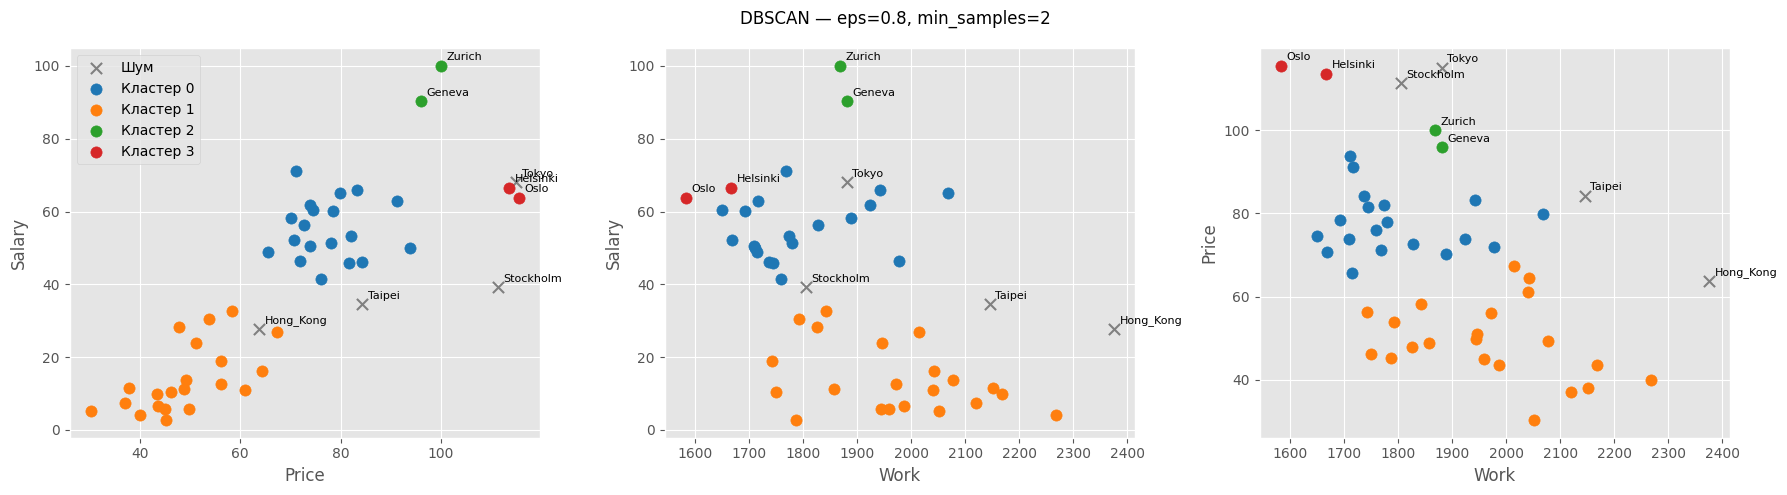

In [ ]:
plot_data = df_knn.copy()
plot_data["cluster"] = dbscan_2.labels_

pairs = [("Price", "Salary"), ("Work", "Salary"), ("Work", "Price")]

colors = {-1: "gray", 0: "tab:blue", 1: "tab:orange", 2: "tab:green", 3: "tab:red"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (x, y) in zip(axes, pairs):
    for cluster, group in plot_data.groupby("cluster"):
        label = "Шум" if cluster == -1 else f"Кластер {cluster}"

        ax.scatter(group[x], group[y], color=colors[cluster], label=label, marker="x" if cluster == -1 else "o", s=65)


        if cluster in [-1, 2, 3]:
            for _, row in group.iterrows():
                ax.annotate(
                    row["City"],
                    (row[x], row[y]),
                    xytext=(4, 4),
                    textcoords="offset points",
                    fontsize=8
                )

    ax.set_xlabel(x)
    ax.set_ylabel(y)

axes[0].legend()
fig.suptitle("DBSCAN — eps=0.8, min_samples=2")
plt.tight_layout()
plt.show()

# Вывод

Финальная кластеризация методом Dbscan c параметрами eps=0.8, min_samples=2

Выделено 4 кластера и четыре шумовых наблюдения (8,3% выборки). Коэффициент силуэта составил 0,464. Выбранные параметры позволяют сохранить две основные группы и выделить две содержательно интерпретируемые пары городов. При увеличении eps до 0,9 основные группы объединяются.

Две большие группы различаются уровнем цен, зарплат и средней продолжительностью работы. Отдельные кластеры образовали Женева и Цюрих с наиболее высокими зарплатами, а также Осло и Хельсинки с высокими ценами и небольшим количеством рабочих часов. Стокгольм, Токио, Гонконг и Тайбэй отнесены к шуму из-за особенностей сочетания показателей при выбранных параметрах.